In [2]:
#Carga los datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
a = pd.read_excel("Productos.xlsx")
a

,Unnamed: 0,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,MANUFACTURER,BRAND,ITEM,...,ATTR2,ATTR3,ID_CATEGORY,CATEGORY_y,CATEGORY,SEGMENT,YEAR,MONTH,WEEK_NUMBER,DATE
0,0,34-22,7501058792808BP2,0.006,1.390000e-01,1.000000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058792808BP2,...,FABRIC TREATMENT,ROSA,1.0,FABRIC TREATMENT and SANIT\n\n,1.0,POWDER,2022.0,8.0,34.0,2022-08-28
1,1,34-22,7501058715883,0.487,1.165190e+02,2.916000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058715883,...,FABRIC TREATMENT,ROSA,1.0,FABRIC TREATMENT and SANIT\n\n,1.0,POWDER,2022.0,8.0,34.0,2022-08-28
2,2,34-22,7702626213774,1.391,6.845300e+01,5.171000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7702626213774,...,FABRIC TREATMENT,ROSA,1.0,FABRIC TREATMENT and SANIT\n\n,1.0,POWDER,2022.0,8.0,34.0,2022-08-28
3,3,34-22,7501058716422,0.022,1.481000e+00,1.833000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058716422,...,FABRIC TREATMENT,ROSA,1.0,FABRIC TREATMENT and SANIT\n\n,1.0,POWDER,2022.0,8.0,34.0,2022-08-28
4,4,34-22,7501058784353,2.037,1.828390e+02,5.375000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058784353,...,FABRIC TREATMENT,ROSA,1.0,FABRIC TREATMENT and SANIT\n\n,1.0,POWDER,2022.0,8.0,34.0,2022-08-28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121998,121998,26-23,7501058757630,1.947,2.354160e+02,2.797000,TOTAL AUTOS SCANNING MEXICO,RECKITT,VANISH,7501058757630,...,FABRIC TREATMENT,ROSA,1.0,FABRIC TREATMENT and SANIT\n\n,1.0,PRETREAT,2023.0,7.0,26.0,2023-07-03
121999,121999,26-23,7501058753441,18.013,4.292890e+02,9.102000,TOTAL AUTOS SCANNING MEXICO,RECKITT,VANISH,7501058753441,...,FABRIC TREATMENT,ROSA,1.0,FABRIC TREATMENT and SANIT\n\n,1.0,POWDER,2023.0,7.0,26.0,2023-07-03
122000,122000,26-23,7702626204208BP1,21.152,2.102760e+02,22.172000,TOTAL AUTOS SCANNING MEXICO,RECKITT,VANISH,7702626204208BP1,...,FABRIC TREATMENT,ROSA,1.0,FABRIC TREATMENT and SANIT\n\n,1.0,POWDER,2023.0,7.0,26.0,2023-07-03
122001,122001,26-23,7501058784346,1.468,3.019730e+02,2.068000,TOTAL AUTOS SCANNING MEXICO,RECKITT,VANISH,7501058784346,...,FABRIC TREATMENT,ROSA,1.0,FABRIC TREATMENT and SANIT\n\n,1.0,POWDER,2023.0,7.0,26.0,2023-07-03


In [44]:
#Identificar las variables clave para el análisis
#veremos las columnas y el tipo de dato para identificar las columnas claves 
a.info()

<class 'pandas.DataFrame'>
RangeIndex: 122003 entries, 0 to 122002
Data columns (total 24 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   Unnamed: 0                   122003 non-null  object        
 1   WEEK                         122002 non-null  str           
 2   ITEM_CODE                    122002 non-null  str           
 3   TOTAL_UNIT_SALES             122003 non-null  float64       
 4   TOTAL_VALUE_SALES            122003 non-null  float64       
 5   TOTAL_UNIT_AVG_WEEKLY_SALES  122003 non-null  float64       
 6   REGION                       122002 non-null  str           
 7   MANUFACTURER                 122002 non-null  str           
 8   BRAND                        122002 non-null  str           
 9   ITEM                         122002 non-null  str           
 10  ITEM_DESCRIPTION             122002 non-null  str           
 11  CATEGORY_x                   122002 n

In [45]:
#Visualizar la distribución de ventas
#Primero saber que columna se puede usar para categorias
print("CATEGORIA ", a["CATEGORY"].unique(), "\n",
"CATEGORIA_y ", a["CATEGORY_y"].unique(), "\n",
"FORMAT ", a["FORMAT"].unique(), "\n",
"BRAND ", a["BRAND"].unique(), "\n",
"SEGMENT ", a["SEGMENT"].unique(), "\n",
"MANUFACTURER ", a["MANUFACTURER"].unique())

CATEGORIA  [ 1. nan] 
 CATEGORIA_y  <ArrowStringArray>
['FABRIC TREATMENT and SANIT\n\n', nan]
Length: 2, dtype: str 
 FORMAT  <ArrowStringArray>
['POLVO', 'LIQUIDO', 'BARRA', 'GEL', 'TOALLAS', nan]
Length: 6, dtype: str 
 BRAND  <ArrowStringArray>
[                   'VANISH',                     'SHOUT',
             'LA VALENCIANA',               'LOS PATITOS',
                 'OXI CLEAN',                  'CLARASOL',
                    'CLOROX',               'DR.BECKMANN',
                  'CLORALEX', 'CUELLOS PUNOS Y MANCHITAS',
                   'BANDERA',                 'BCLORHADA',
                  'PURO SOL',        'OTHERS MARCA UNIF.',
                      'TIDE',                     'LYSOL',
                 'BLANCATEL',                  'CLORALUZ',
                   'CLORTEX',                    'PATITO',
                   'SANYTOL',                    'IBERIA',
               'LA JAPONESA',                    'HARPIC',
                         nan]
Length: 25, d

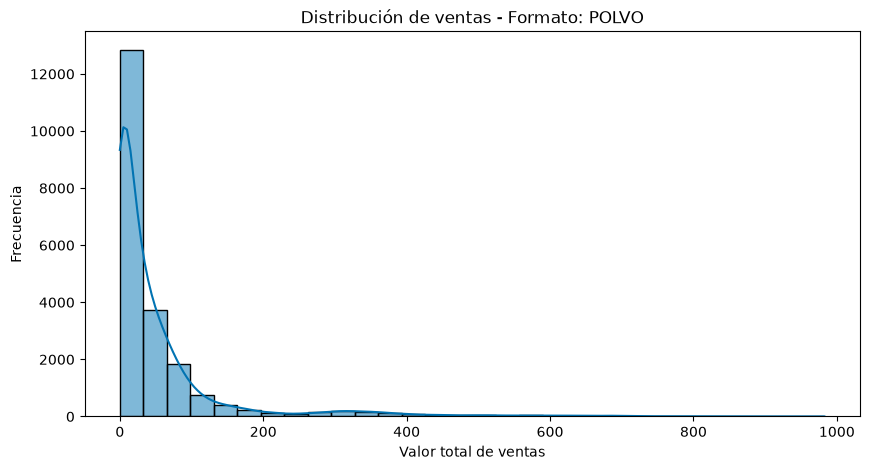

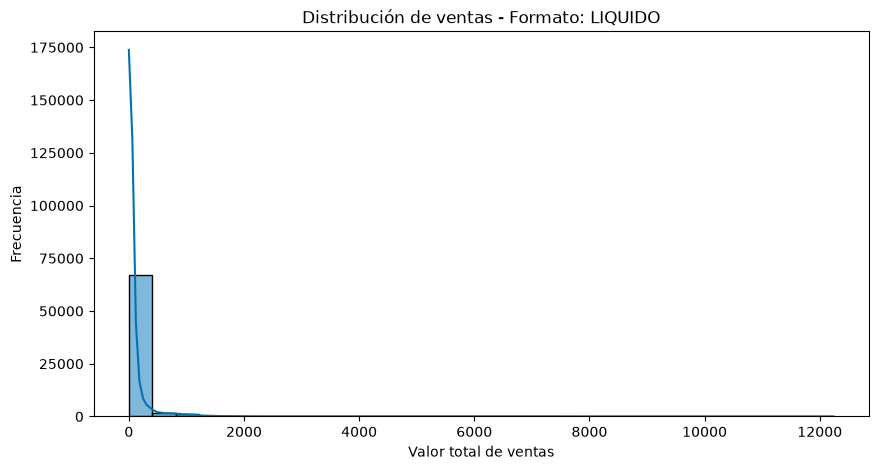

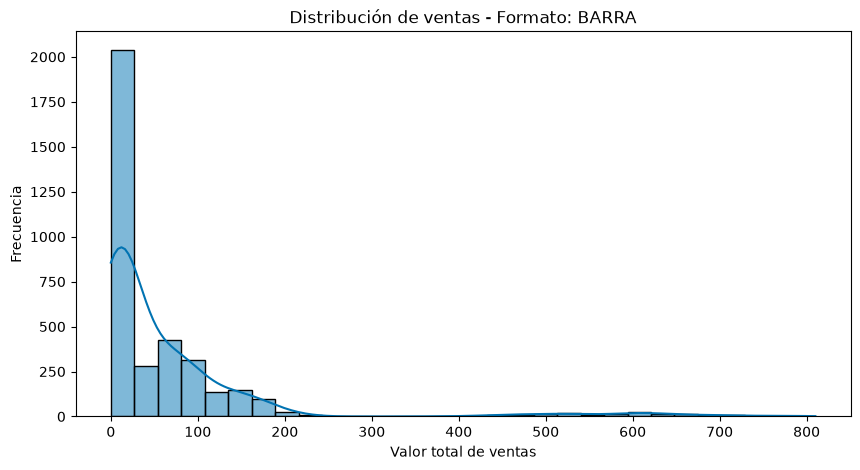

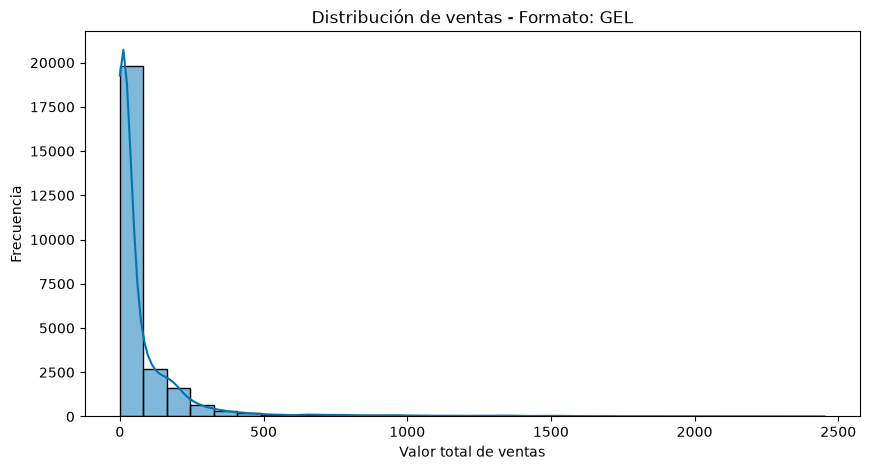

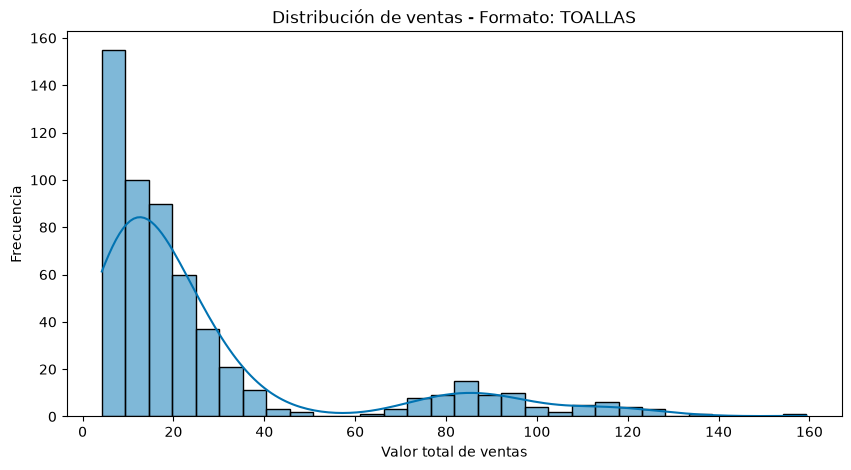

In [57]:
#Usaremos histograma  para visualizar la distribución de ventas por diferentes categorías usando la columna Formato, usando separada ya que unificada, no se disquingue bien la información.
formatos = a["FORMAT"].dropna().unique()

for formato in formatos:
    plt.figure(figsize=(10, 5))
    
    sns.histplot(
        data=a[a["FORMAT"] == formato],
        x="TOTAL_VALUE_SALES",
        bins=30,
        kde=True
    )
    
    plt.title(f"Distribución de ventas - Formato: {formato}")
    plt.xlabel("Valor total de ventas")
    plt.ylabel("Frecuencia")
    
    plt.savefig(f"histograma_ventas_{formato}.png")
    
    plt.show()
    plt.close()

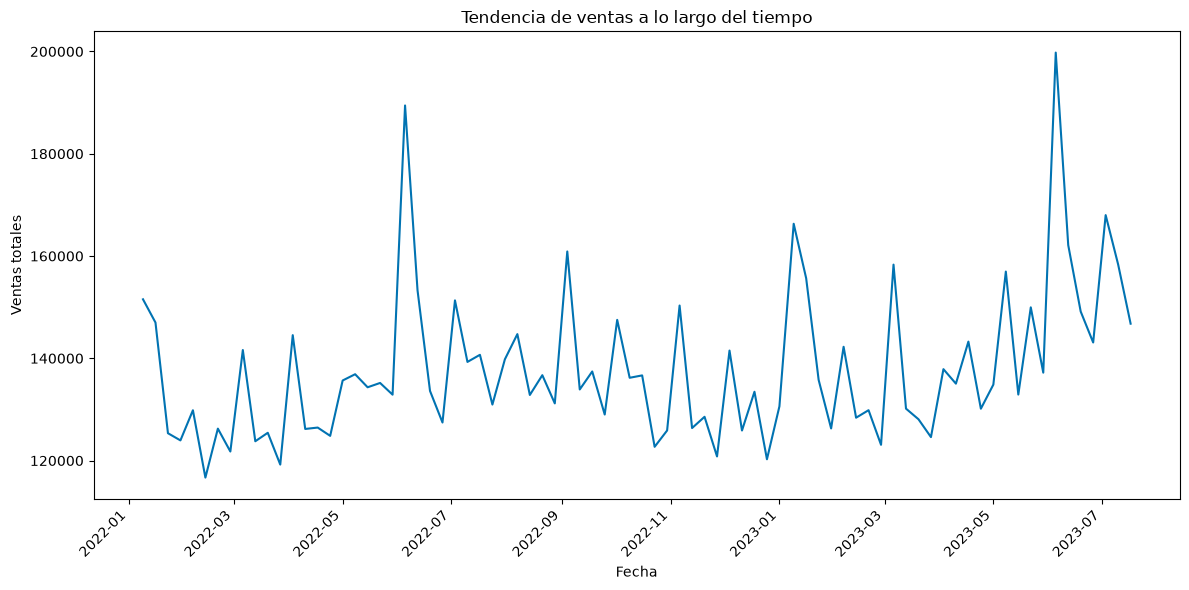

In [56]:
#Analizar la tendencia de ventas en el tiempo, as tendencias de ventas a lo largo del tiempo. Filtra las ventas por diferentes productos, regiones o segmentos para analizar cómo han cambiado las ventas a lo largo del tiempo
ventas_fecha = (a.groupby("DATE", as_index=False)["TOTAL_VALUE_SALES"].sum())

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=ventas_fecha,
    x="DATE",
    y="TOTAL_VALUE_SALES"
)

plt.title("Tendencia de ventas a lo largo del tiempo")
plt.xlabel("Fecha")
plt.ylabel("Ventas totales")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig("Tendencia_de_venta_largo_tiempo.png", dpi=300,  bbox_inches="tight")

plt.show()

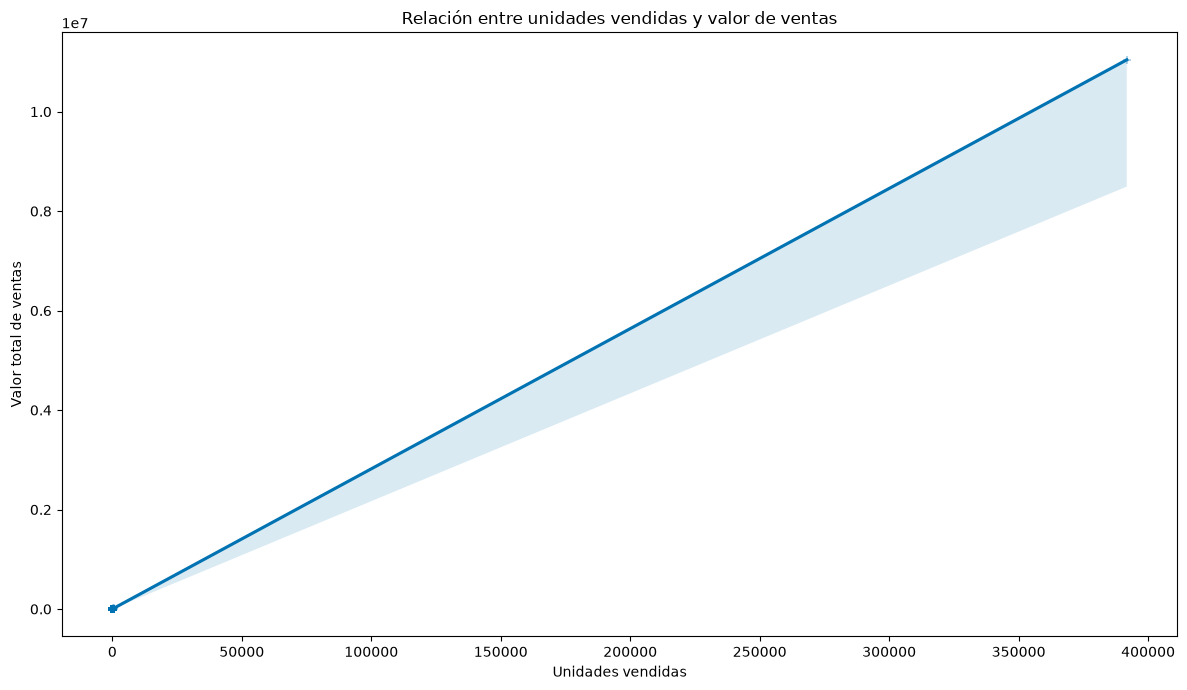

In [55]:
#Explorar la relación entre diferentes variables seria cantidad de unidades vendidas con valor total de las ventas
plt.figure(figsize=(12, 7))

sns.regplot(
    data=a,
    y="TOTAL_VALUE_SALES",
    x="TOTAL_UNIT_SALES",
    marker="+",
    scatter_kws={"alpha": 0.3}
)

plt.title("Relación entre unidades vendidas y valor de ventas")
plt.xlabel("Unidades vendidas")
plt.ylabel("Valor total de ventas")

plt.tight_layout()

plt.savefig("Relacion_unidades_vendidas_y_valor_ventas.png",   dpi=300,  bbox_inches="tight")

plt.show()

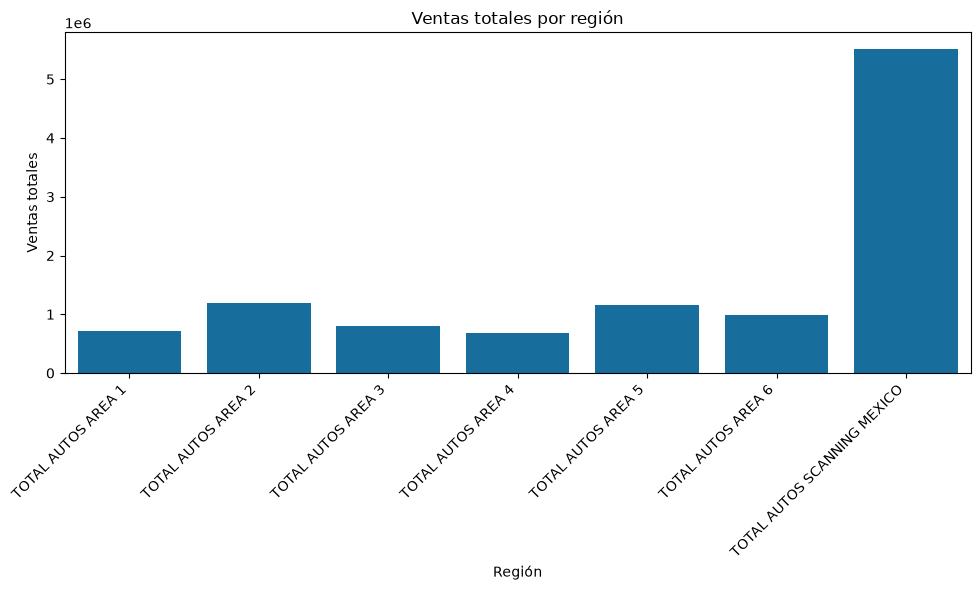

In [54]:
#Visualizar la distribución geográfica de las venta gráficos de barras apiladas para visualizar las ventas por región
ventas_region = (a.groupby("REGION")["TOTAL_VALUE_SALES"].sum().reset_index())
plt.figure(figsize=(10, 6))

sns.barplot(
    data=ventas_region,
    x="REGION",
    y="TOTAL_VALUE_SALES"
)

plt.title("Ventas totales por región")
plt.xlabel("Región")
plt.ylabel("Ventas totales")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig("venta_totales_región.png" , dpi=300, bbox_inches="tight")

plt.show()

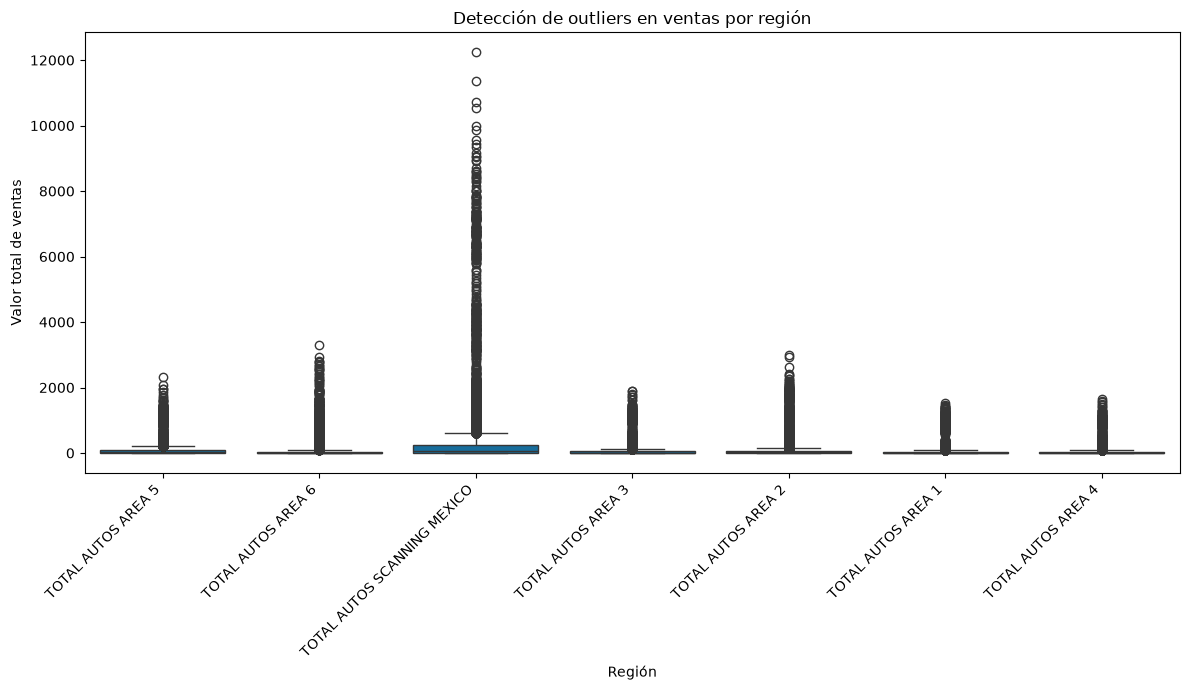

In [53]:
#Identificar posibles outliers y anomalías los datos de ventas por producto, categoría o región
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=a,
    x="REGION",
    y="TOTAL_VALUE_SALES"
)

plt.title("Detección de outliers en ventas por región")
plt.xlabel("Región")
plt.ylabel("Valor total de ventas")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig("Deteccion_outliers_ventas_region.png", dpi=300, bbox_inches="tight")

plt.show()

1. Ventas por categoría/formato
En la primera gráfica se generaron varias visualizaciones para dividir los datos por categoría, utilizando la variable FORMAT, ya que al mostrar todas las categorías en una sola gráfica no se distinguían correctamente. Se calculó el valor total de las ventas para identificar qué formato presenta el mayor volumen de ventas.

2. Ventas totales por fecha
En la segunda gráfica se analizaron las ventas totales a través del tiempo. Esto permite identificar los meses o años en los que se registró un mayor volumen de ventas y observar el comportamiento de las ventas durante el periodo analizado.

3. Relación entre unidades vendidas y valor de ventas
En la tercera gráfica se analizó la relación entre la cantidad de unidades vendidas y el valor total de las ventas. Esto permite observar si un incremento en las unidades vendidas está relacionado con un mayor valor de ventas.

4. Ventas totales por región
En la cuarta gráfica se calcularon las ventas totales por región con el objetivo de comparar el desempeño de cada una e identificar qué región presenta el mayor volumen de ventas y cuáles tienen un menor desempeño.

5. Detección de outliers en ventas por región
En la quinta gráfica busca las ventas que sean inusualmente altas o bajas comparadas con las demás ventas de esa región